<div align="center">

## **DS201.R11 - DEEP LEARNING TRONG KHDL**

### **BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP**
</div>

**Họ và tên:** Võ Hạnh Nguyên

**MSSV:** 24521218

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

---
## **1. Cài đặt và cấu hình**

Phần này dùng chung cho cả bốn bài: import thư viện, tải dữ liệu, chia train/val/test, khung huấn luyện và đánh giá.

**Quy ước của cả notebook**
- Optimizer: Adam. Seed: 42.
- Tập **val = 20% tập train**, chia bằng `random_split(..., generator=torch.Generator().manual_seed(42))` một lần duy nhất; tập test là thư mục `test/` của dataset.
- 4 độ đo trên tập test: accuracy, precision, recall, F1. Precision, recall và F1 lấy trung bình **macro** trên 21 lớp. Macro-F1 là độ đo chính.
- Chọn checkpoint theo **macro-F1 trên val** (không dùng test để chọn), rồi mới đánh giá trên test.

In [1]:
import os
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, classification_report, confusion_matrix)

In [2]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("torch  :", torch.__version__)
print("device :", device)

torch  : 2.11.0+cu130
device : cuda


In [3]:
def n_params(module, trainable_only=False):
    ps = module.parameters()
    if trainable_only:
        ps = (p for p in module.parameters() if p.requires_grad)
    return sum(p.numel() for p in ps)


def show(label, t):
    print(f"{label:<28} {tuple(t.shape)}")

## **2. Tải và load VinaFood21**

In [4]:
# Tải dữ liệu và giải nén
zip_file = "VinaFood21.zip"
data_dir = "/content/VinaFood21"
url = "https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR"

# Kiểm tra nếu chưa có dữ liệu thì mới tải và giải nén
if not os.path.exists(data_dir):
    # Cập nhật gdown và tải file từ Google Drive ID
    !pip install -q --upgrade gdown
    !gdown {url} -O {zip_file}
    !unzip -q {zip_file} -d /content/

    # Xóa file zip sau khi giải nén để tiết kiệm bộ nhớ Colab
    if os.path.exists(zip_file):
        os.remove(zip_file)

    print("Hoàn tất chuẩn bị dữ liệu!")
else:
    print("Dữ liệu đã sẵn sàng!")

Downloading...
From (original): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR
From (redirected): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR&confirm=t&uuid=0af7a03c-e628-4908-afcf-d7093dd8f9ee
To: /content/VinaFood21.zip
100% 2.71G/2.71G [00:44<00:00, 60.9MB/s]
Hoàn tất chuẩn bị dữ liệu!


In [5]:
# Kiểm tra cấu trúc thư mục: cần có train/ và test/ (mỗi lớp một thư mục con)
DATA_ROOT = Path(data_dir)
print("Thư mục gốc:", DATA_ROOT, "->", sorted(p.name for p in DATA_ROOT.iterdir()))
assert (DATA_ROOT / "train").is_dir() and (DATA_ROOT / "test").is_dir(), (
    "Không thấy train/ hoặc test/ trong " + str(DATA_ROOT) + ". "
    "Xem lại cấu trúc sau khi giải nén và sửa biến data_dir cho đúng.")

Thư mục gốc: /content/VinaFood21 -> ['README.txt', 'test', 'train']


In [ ]:
# Cấu hình chung và chia val = 20% train (một lần duy nhất, dùng chung cho cả 4 bài)
BATCH = 32
VAL_RATIO = 0.2
NUM_WORKERS = 2
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # mean/std của ImageNet

_base = datasets.ImageFolder(DATA_ROOT / "train")
CLASSES = _base.classes                  # tên lớp theo bảng chữ cái
NUM_CLASSES = len(CLASSES)
targets = np.array(_base.targets)

n_total = len(_base)
n_val = int(VAL_RATIO * n_total)
n_train = n_total - n_val
train_part, val_part = random_split(range(n_total), [n_train, n_val],
                                    generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = list(train_part.indices), list(val_part.indices)

n_test = len(datasets.ImageFolder(DATA_ROOT / "test"))
print("số lớp   :", NUM_CLASSES)
print("thứ tự lớp:", CLASSES[:5], "...")
print(f"train: {len(train_idx):,} | val: {len(val_idx):,} | test: {n_test:,}")

cnt = np.bincount(targets, minlength=NUM_CLASSES)
print(f"số ảnh/lớp trong train gốc: min {cnt.min()}, max {cnt.max()}, tỉ lệ max/min = {cnt.max() / cnt.min():.2f}")
assert not set(train_idx) & set(val_idx)

số lớp   : 21
thứ tự lớp: ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron'] ...
train: 8,036 | val: 2,008 | test: 6,682
số ảnh/lớp trong train gốc: min 215, max 910, tỉ lệ max/min = 4.23


In [7]:
# Transform và DataLoader theo từng cỡ ảnh. Augmentation chỉ áp cho train
def make_transforms(img_size, augment=True):
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    if augment:
        train_tf = transforms.Compose([
            transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(15),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
    else:
        train_tf = eval_tf
    return train_tf, eval_tf


def make_loaders(img_size, augment=True, batch=BATCH):
    train_tf, eval_tf = make_transforms(img_size, augment)

    # Hai ImageFolder trỏ cùng thư mục train/ nhưng khác transform, lấy theo cùng chỉ số
    # đã chia ở trên: train_ds có augment, val_ds chỉ resize + chuẩn hoá.
    train_full = datasets.ImageFolder(DATA_ROOT / "train", transform=train_tf)
    val_full = datasets.ImageFolder(DATA_ROOT / "train", transform=eval_tf)
    test_ds = datasets.ImageFolder(DATA_ROOT / "test", transform=eval_tf)
    assert train_full.classes == test_ds.classes == CLASSES, "train và test lệch tên lớp"

    train_ds = Subset(train_full, train_idx)
    val_ds = Subset(val_full, val_idx)

    g = torch.Generator().manual_seed(SEED)
    kw = dict(batch_size=batch, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
    train_dl = DataLoader(train_ds, shuffle=True, generator=g, **kw)
    val_dl = DataLoader(val_ds, shuffle=False, **kw)
    test_dl = DataLoader(test_ds, shuffle=False, **kw)
    return train_dl, val_dl, test_dl


# Kiểm tra shape của một ảnh và một batch trước khi đưa vào mô hình
_tr, _va, _te = make_loaders(64)
xb, yb = next(iter(_tr))
show("một batch vào model", xb)
show("nhãn", yb)
print(f"số batch: train {len(_tr)}, val {len(_va)}, test {len(_te)}")
assert xb.shape[1:] == (3, 64, 64)
del _tr, _va, _te

một batch vào model          (32, 3, 64, 64)
nhãn                         (32,)
số batch: train 252, val 63, test 209


---
## **3. Khung huấn luyện và đánh giá dùng chung**

In [8]:
# Số epoch và learning rate cho từng bài (chỉnh ở đây nếu cần chạy nhanh hơn)
EPOCHS_LENET = 20       # Bài 1
EPOCHS_GOOGLENET = 20   # Bài 2
EPOCHS_RESNET18 = 30    # Bài 3*
EPOCHS_RESNET50 = 10    # Bài 4* (mỗi chế độ)
LR_SCRATCH = 1e-3       # Bài 1, 2, 3
LR_FE, LR_FT = 1e-3, 1e-4   # Bài 4: feature extraction / fine-tuning

In [9]:
# Huấn luyện một epoch
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()                     # bật dropout, BN dùng thống kê batch
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total


# Đánh giá, trả về cả y_true và y_pred để tính macro-F1 và confusion matrix
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()                      # tắt dropout, BN dùng thống kê tích luỹ
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()
    return running / total, correct / total, y_true, y_pred

In [10]:
# Vòng huấn luyện nhiều epoch, chọn checkpoint theo macro-F1 trên val
def fit(model, train_dl, val_dl, lr, epochs, tag=""):
    criterion = nn.CrossEntropyLoss()
    # chỉ đưa tham số cần học vào optimizer (quan trọng với feature extraction ở Bài 4)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr)

    rows, best_f1, best_epoch, best_state = [], -1.0, 0, None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
        va_loss, va_acc, yt, yp = evaluate(model, val_dl, criterion, device)
        if device.type == "cuda":
            torch.cuda.synchronize()
        dt = time.time() - t0

        va_f1 = f1_score(yt, yp, average="macro", zero_division=0)
        rows.append(dict(epoch=ep, train_loss=tr_loss, val_loss=va_loss,
                         train_acc=tr_acc, val_acc=va_acc, val_f1=va_f1, sec=dt))
        if va_f1 > best_f1:
            best_f1, best_epoch = va_f1, ep
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"{tag} epoch {ep:>2}/{epochs}  train {tr_loss:.4f}/{tr_acc:.4f}   "
              f"val {va_loss:.4f}/{va_acc:.4f}  F1 {va_f1:.4f}   {dt:.1f}s")

    model.load_state_dict(best_state)          # quay về epoch có val macro-F1 tốt nhất
    hist = pd.DataFrame(rows)
    print(f"-> chọn epoch {best_epoch} (val macro-F1 {best_f1:.4f}), trung bình {hist.sec.mean():.1f} giây/epoch")
    return dict(history=hist, best_epoch=best_epoch, sec_per_epoch=float(hist.sec.mean()))

In [11]:
# Đo trên test: 4 độ đo, F1 từng lớp, confusion matrix
def test_eval(model, test_dl):
    criterion = nn.CrossEntropyLoss()
    loss, _, yt, yp = evaluate(model, test_dl, criterion, device)
    p, r, f1, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
    metrics = dict(accuracy=accuracy_score(yt, yp), precision=p, recall=r, f1_macro=f1)

    rep = classification_report(yt, yp, labels=list(range(NUM_CLASSES)), target_names=CLASSES,
                                output_dict=True, zero_division=0)
    per_class = pd.DataFrame(rep).T.loc[CLASSES, ["precision", "recall", "f1-score", "support"]]
    per_class["support"] = per_class["support"].astype(int)
    cm = confusion_matrix(yt, yp, labels=list(range(NUM_CLASSES)))
    return dict(metrics=metrics, per_class=per_class, cm=cm, test_loss=loss)


def plot_history(hist, title, ax=None, mark=None):
    ax = ax or plt.gca()
    ax.plot(hist.epoch, hist.train_loss, label="train loss")
    ax.plot(hist.epoch, hist.val_loss, label="val loss")
    if mark is not None:
        ax.axvline(mark, color="gray", ls="--", lw=1, label=f"tách nhau ~ epoch {mark}")
    ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_title(title); ax.legend()


def plot_cm(cm, title):
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues", annot=True, fmt="d",
                annot_kws={"size": 6}, cbar=False)
    plt.xlabel("dự đoán"); plt.ylabel("thực tế"); plt.title(title)
    plt.xticks(rotation=90); plt.tight_layout(); plt.show()


def top_confusions(cm, k=8):
    off = cm.copy()
    np.fill_diagonal(off, 0)
    pairs = [(off[i, j], CLASSES[i], CLASSES[j]) for i in range(len(cm)) for j in range(len(cm)) if off[i, j] > 0]
    pairs.sort(reverse=True)
    return pd.DataFrame(pairs[:k], columns=["số ảnh", "thực tế", "bị đoán thành"])


RESULTS = {}      # name -> dict(resize, params, sec/epoch, 4 độ đo), dùng cho bảng tổng hợp cuối


def run_experiment(name, model, loaders, lr, epochs, resize, plot=True, show_cm=True):
    """Huấn luyện, chọn checkpoint theo val, đánh giá trên test, in/vẽ kết quả và lưu vào RESULTS."""
    train_dl, val_dl, test_dl = loaders
    model = model.to(device)
    print(f"[{name}] {n_params(model):,} tham số, trainable {n_params(model, True):,}, lr={lr}, {epochs} epoch")
    fit_out = fit(model, train_dl, val_dl, lr, epochs, tag=name)
    te = test_eval(model, test_dl)

    m = te["metrics"]
    print(f"\n[{name}] kết quả trên TEST:")
    print(pd.Series(m).to_frame("giá trị").round(4).T.to_string())

    if plot:
        plt.figure(figsize=(6, 4))
        plot_history(fit_out["history"], f"{name}: loss theo epoch")
        plt.tight_layout(); plt.show()
    if show_cm:
        plot_cm(te["cm"], f"{name}: confusion matrix (test)")

    RESULTS[name] = dict(resize=resize, params=n_params(model), sec_per_epoch=fit_out["sec_per_epoch"],
                         best_epoch=fit_out["best_epoch"], **m)
    return dict(model=model, **fit_out, **te)


print("Khung huấn luyện đã sẵn sàng.")

Khung huấn luyện đã sẵn sàng.


---
## **Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).**

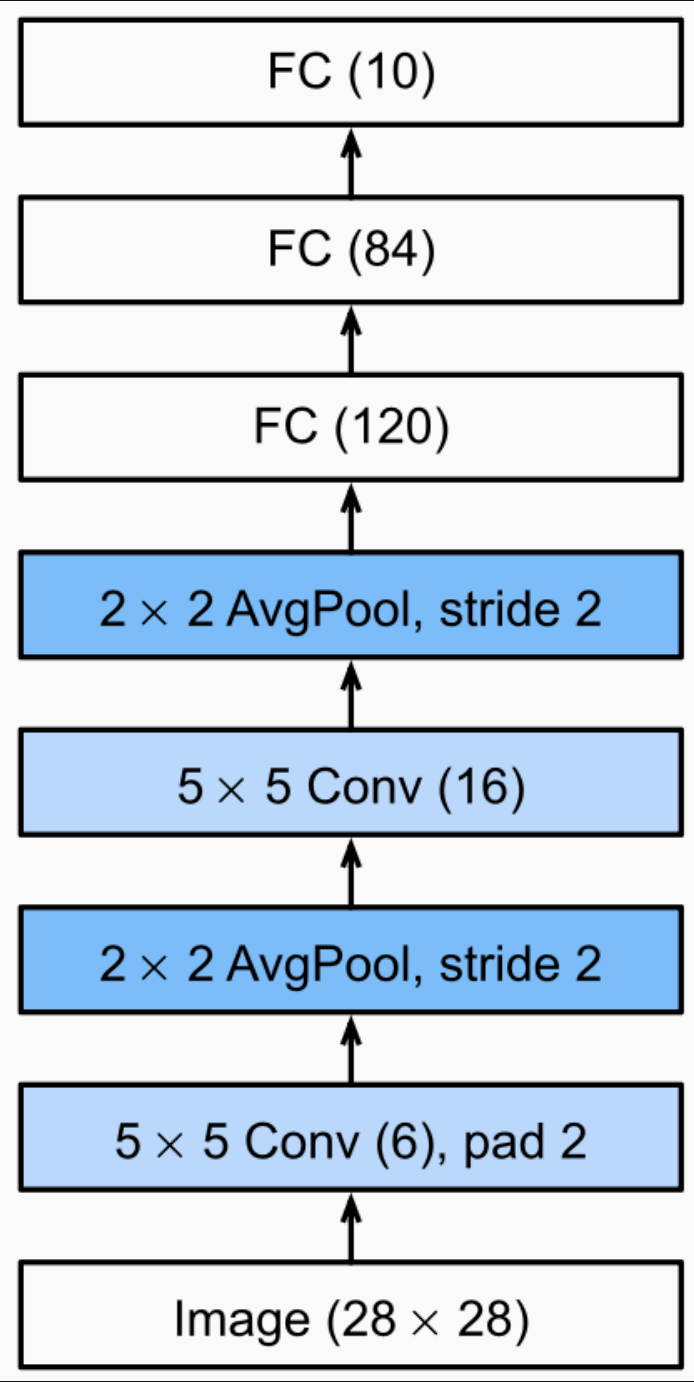

**Thiết kế (theo B.3):** 7 layer C1 → S2 → C3 → S4 → F5 → F6 → OUT, ảnh vào 64×64×3, C1 không padding, 21 lớp, ReLU. Chạy hai lần: `AvgPool2d(2, 2)` rồi `MaxPool2d(2, 2)` để so sánh.

### *1.1 Mô hình, số tham số và bảng tham số*

In [12]:
# Định nghĩa LeNet-5 với số channel vào, kích thước ảnh và số lớp tham số hoá
class LeNet5(nn.Module):
    def __init__(self, in_ch=3, img=64, num_classes=21, pool="avg"):
        super().__init__()
        Pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)
        self.s2 = Pool(2, 2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = Pool(2, 2)

        n_flat = self._flat_dim(in_ch, img)
        self.f5 = nn.Linear(n_flat, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)
        self.n_flat = n_flat

    def _flat_dim(self, in_ch, img):
        # Dò số chiều sau S4 bằng một forward giả, tránh tính tay
        with torch.no_grad():
            z = torch.zeros(1, in_ch, img, img)
            z = self.s4(self.c3(self.s2(self.c1(z))))
        return int(z.flatten(1).shape[1])

    def forward(self, x):
        x = self.s2(torch.relu(self.c1(x)))
        x = self.s4(torch.relu(self.c3(x)))
        x = x.flatten(1)
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))
        return self.out(x)


# Số tham số của cấu hình Bài 1
lenet = LeNet5(in_ch=3, img=64, num_classes=NUM_CLASSES)
print("số chiều sau flatten:", lenet.n_flat)
print("tổng tham số        :", f"{n_params(lenet):,}")
if NUM_CLASSES == 21:
    assert lenet.n_flat == 2704 and n_params(lenet) == 339_421

số chiều sau flatten: 2704
tổng tham số        : 339,421


In [13]:
# Bảng shape và tham số của từng layer
def layer_table(model, img, in_ch=3):
    x = torch.zeros(1, in_ch, img, img)
    rows, total = [], 0
    for name, layer in [("C1", model.c1), ("S2", model.s2),
                        ("C3", model.c3), ("S4", model.s4)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, "x".join(map(str, tuple(x.shape)[1:])), p))
    x = x.flatten(1)
    rows.append(("flatten", str(x.shape[1]), 0))
    for name, layer in [("F5", model.f5), ("F6", model.f6), ("OUT", model.out)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, str(x.shape[1]), p))
    return rows, total


rows, total = layer_table(lenet, 64)
print(f"{'layer':<10}{'output':<16}{'tham số':>12}")
for name, shape, p in rows:
    print(f"{name:<10}{shape:<16}{p:>12,}")
print(f"{'TỔNG':<10}{'':<16}{total:>12,}")
assert total == n_params(lenet)

# Đối chiếu tính tay (đủ bias): C1 = (5*5*3+1)*6, C3 = (5*5*6+1)*16, F5 = 2704*120+120, ...
hand = {"C1": (5*5*3 + 1) * 6, "C3": (5*5*6 + 1) * 16,
        "F5": lenet.n_flat * 120 + 120, "F6": 120 * 84 + 84, "OUT": 84 * NUM_CLASSES + NUM_CLASSES}
for name, shape, p in rows:
    if name in hand:
        assert hand[name] == p, (name, hand[name], p)
print("\nTính tay khớp với code ở mọi layer có tham số.")

layer     output               tham số
C1        6x60x60                  456
S2        6x30x30                    0
C3        16x26x26               2,416
S4        16x13x13                   0
flatten   2704                       0
F5        120                  324,600
F6        84                    10,164
OUT       21                     1,785
TỔNG                           339,421

Tính tay khớp với code ở mọi layer có tham số.


### *1.2 Huấn luyện và đánh giá (AvgPool, rồi MaxPool)*

[LeNet-5 (AvgPool)] 339,421 tham số, trainable 339,421, lr=0.001, 20 epoch


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


LeNet-5 (AvgPool) epoch  1/20  train 2.7899/0.1480   val 2.5350/0.2286  F1 0.1521   121.1s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


LeNet-5 (AvgPool) epoch  2/20  train 2.5632/0.2078   val 2.4702/0.2555  F1 0.1845   108.1s


...

LeNet-5 (AvgPool) epoch 18/20  train 1.9084/0.4088   val 2.1683/0.3471  F1 0.3249   110.2s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


LeNet-5 (AvgPool) epoch 19/20  train 1.8968/0.4136   val 2.1291/0.3690  F1 0.3470   109.5s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


LeNet-5 (AvgPool) epoch 20/20  train 1.8651/0.4177   val 2.1447/0.3625  F1 0.3434   107.4s
-> chọn epoch 19 (val macro-F1 0.3470), trung bình 110.0 giây/epoch

[LeNet-5 (AvgPool)] kết quả trên TEST:
         accuracy  precision  recall  f1_macro
giá trị    0.3113     0.3066  0.2988    0.2925


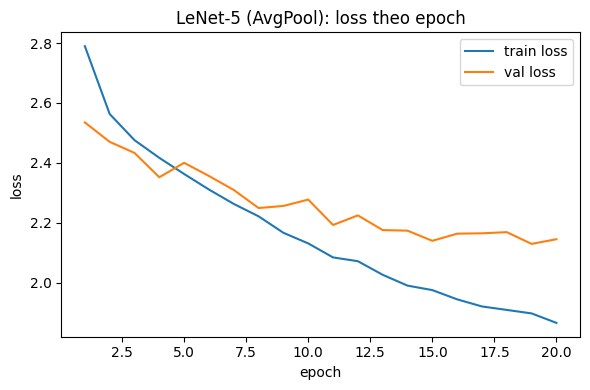

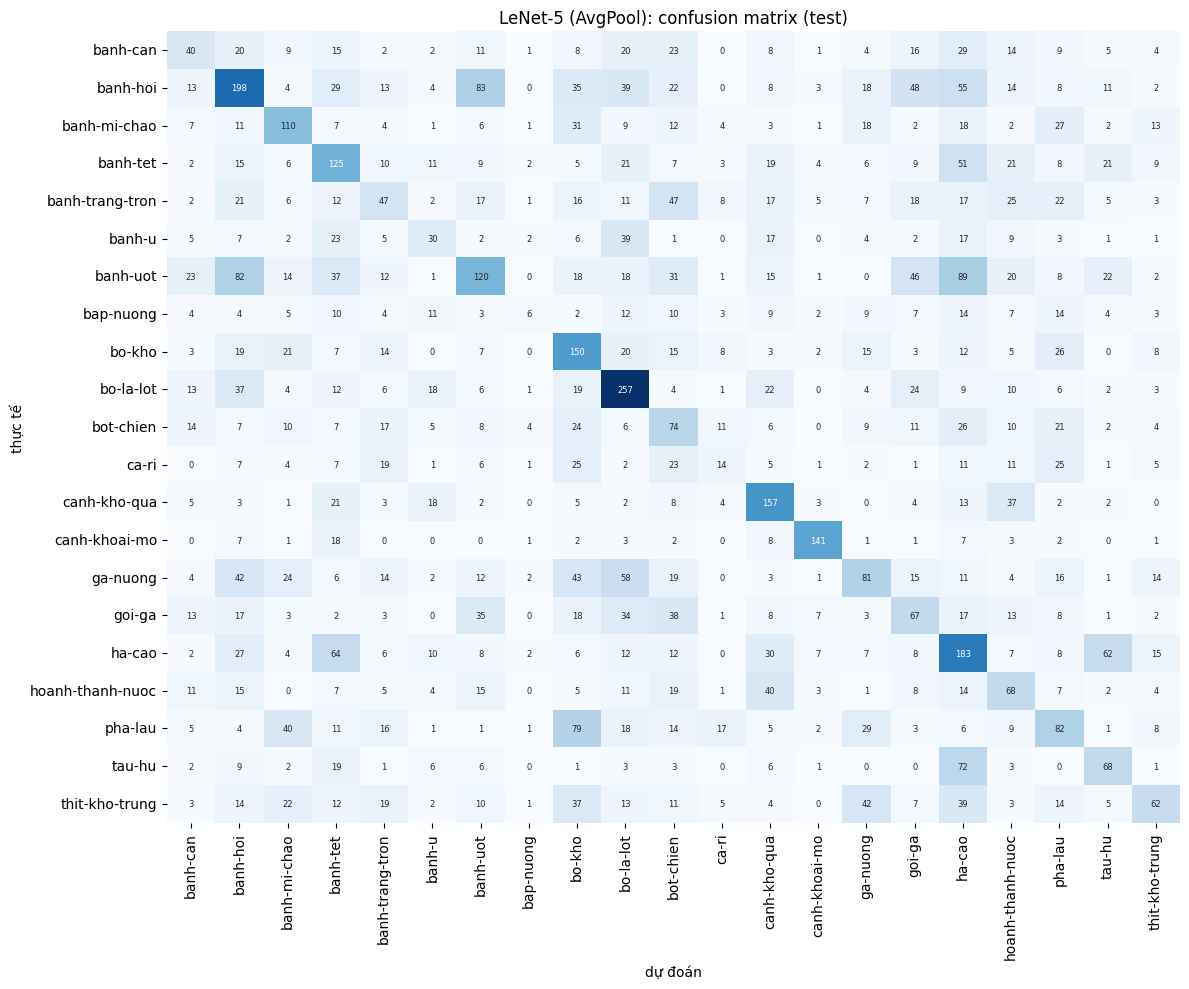

In [14]:
# Huấn luyện LeNet-5 bản AvgPool
loaders64 = make_loaders(64, augment=True)

set_seed()
out_lenet_avg = run_experiment("LeNet-5 (AvgPool)", LeNet5(3, 64, NUM_CLASSES, pool="avg"),
                               loaders64, LR_SCRATCH, EPOCHS_LENET, "64×64")

[LeNet-5 (MaxPool)] 339,421 tham số, trainable 339,421, lr=0.001, 20 epoch


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


LeNet-5 (MaxPool) epoch  1/20  train 2.8129/0.1456   val 2.6244/0.2047  F1 0.1298   104.2s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


LeNet-5 (MaxPool) epoch  2/20  train 2.5810/0.2088   val 2.4736/0.2380  F1 0.1703   104.4s


...

LeNet-5 (MaxPool) epoch 18/20  train 1.8623/0.4260   val 2.1345/0.3601  F1 0.3340   106.0s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


LeNet-5 (MaxPool) epoch 19/20  train 1.8391/0.4335   val 2.0784/0.3760  F1 0.3498   107.0s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


LeNet-5 (MaxPool) epoch 20/20  train 1.8272/0.4365   val 2.0882/0.3616  F1 0.3412   106.2s
-> chọn epoch 19 (val macro-F1 0.3498), trung bình 106.2 giây/epoch

[LeNet-5 (MaxPool)] kết quả trên TEST:
         accuracy  precision  recall  f1_macro
giá trị    0.3221     0.3172  0.3098    0.2967


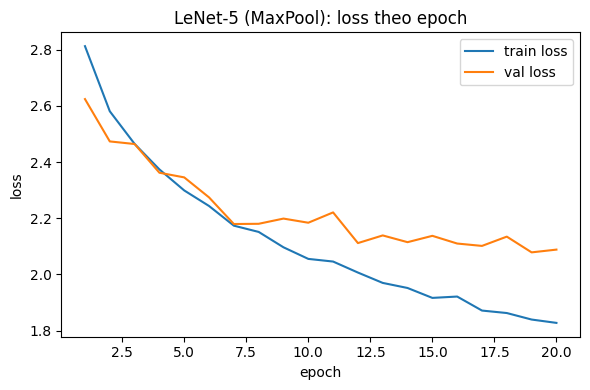

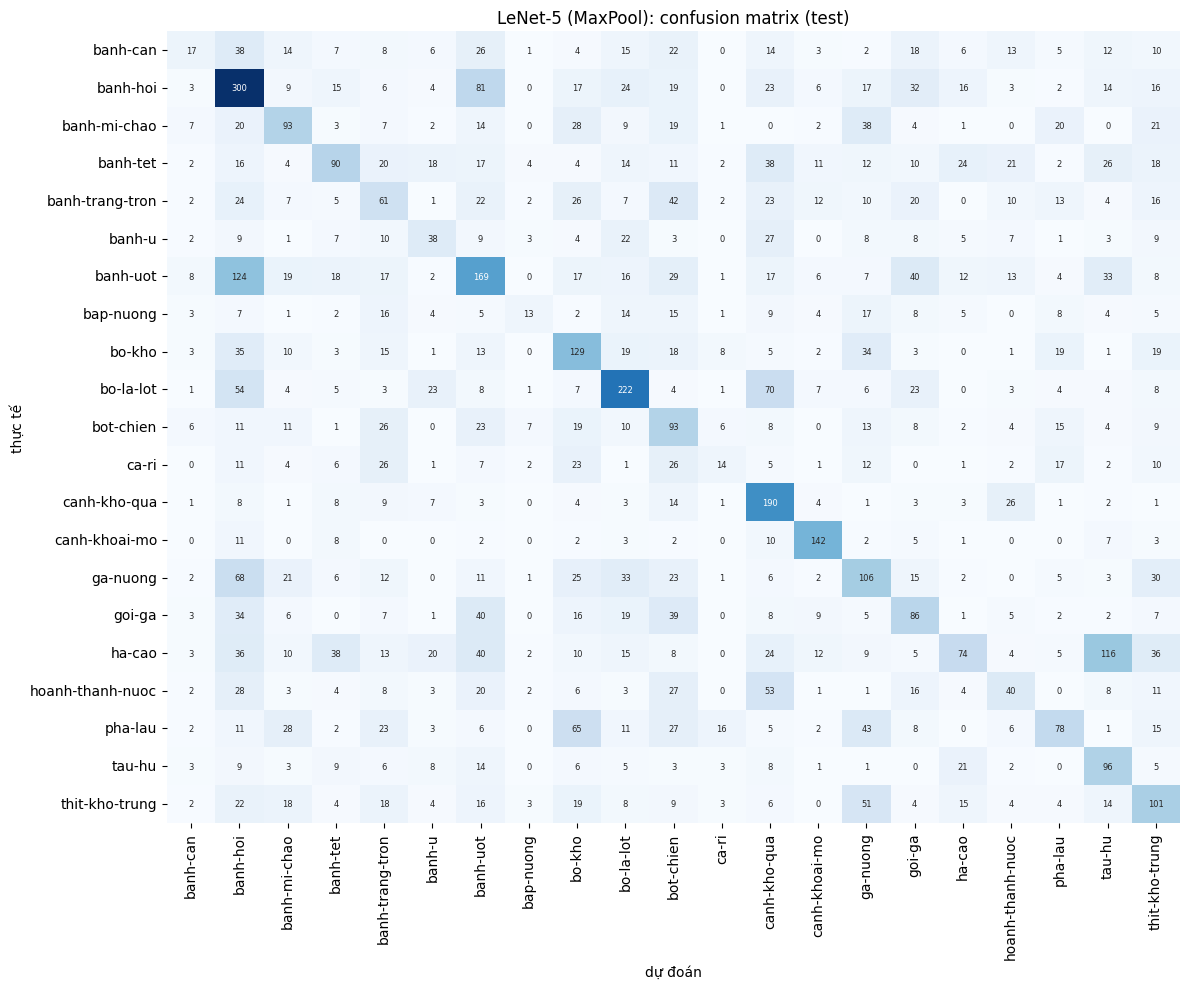

In [15]:
# Huấn luyện lại với MaxPool (cùng seed, cùng dữ liệu, chỉ đổi lớp pooling)
set_seed()
out_lenet_max = run_experiment("LeNet-5 (MaxPool)", LeNet5(3, 64, NUM_CLASSES, pool="max"),
                               loaders64, LR_SCRATCH, EPOCHS_LENET, "64×64")

### *1.3 Kết quả: 4 độ đo, F1 từng lớp, so sánh AvgPool với MaxPool*

In [16]:
# Bảng 4 độ đo trên tập test và macro-F1 của hai bản pooling
cols = ["accuracy", "precision", "recall", "f1_macro"]
tbl = pd.DataFrame({k: RESULTS[k] for k in ["LeNet-5 (AvgPool)", "LeNet-5 (MaxPool)"]}).T
print("Số tham số: AvgPool và MaxPool đều", f"{int(tbl.params.iloc[0]):,}", "(pooling không có tham số)")
display(tbl[cols].astype(float).round(4))

# Bảng F1 từng lớp (test)
f1_cls = pd.DataFrame({
    "F1 AvgPool": out_lenet_avg["per_class"]["f1-score"],
    "F1 MaxPool": out_lenet_max["per_class"]["f1-score"],
    "số ảnh test": out_lenet_avg["per_class"]["support"],
}).round(4)
f1_cls.loc["macro avg"] = [out_lenet_avg["metrics"]["f1_macro"], out_lenet_max["metrics"]["f1_macro"], f1_cls["số ảnh test"].sum()]
display(f1_cls)

# Các cặp lớp bị nhầm nhiều nhất của bản tốt hơn
best = out_lenet_avg if out_lenet_avg["metrics"]["f1_macro"] >= out_lenet_max["metrics"]["f1_macro"] else out_lenet_max
print("Các cặp bị nhầm nhiều nhất của bản có macro-F1 cao hơn:")
display(top_confusions(best["cm"]))

Số tham số: AvgPool và MaxPool đều 339,421 (pooling không có tham số)


,accuracy,precision,recall,f1_macro
LeNet-5 (AvgPool),0.3113,0.3066,0.2988,0.2925
LeNet-5 (MaxPool),0.3221,0.3172,0.3098,0.2967


,F1 AvgPool,F1 MaxPool,số ảnh test
banh-can,0.194200,0.108600,241.0
banh-hoi,0.337600,0.404600,607.0
banh-mi-chao,0.378700,0.334500,289.0
banh-tet,0.306700,0.297500,364.0
banh-trang-tron,0.177700,0.196800,309.0
banh-u,0.196700,0.236000,176.0
banh-uot,0.258900,0.305600,560.0
bap-nuong,0.071000,0.141300,143.0
bo-kho,0.343600,0.334600,338.0
bo-la-lot,0.482200,0.476900,458.0


Các cặp bị nhầm nhiều nhất của bản có macro-F1 cao hơn:


,số ảnh,thực tế,bị đoán thành
0,124,banh-uot,banh-hoi
1,116,ha-cao,tau-hu
2,81,banh-hoi,banh-uot
3,70,bo-la-lot,canh-kho-qua
4,68,ga-nuong,banh-hoi
5,65,pha-lau,bo-kho
6,54,bo-la-lot,banh-hoi
7,53,hoanh-thanh-nuoc,canh-kho-qua


## **Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).**

**Inception Blocks**

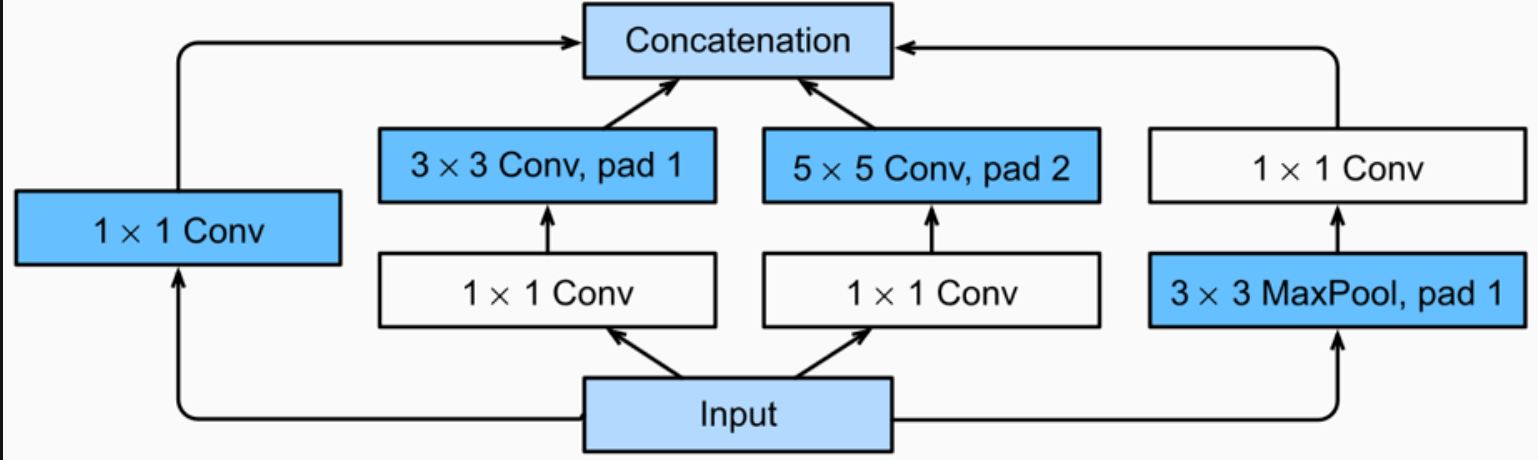

**GoogLeNet (Multi-branch Network)**

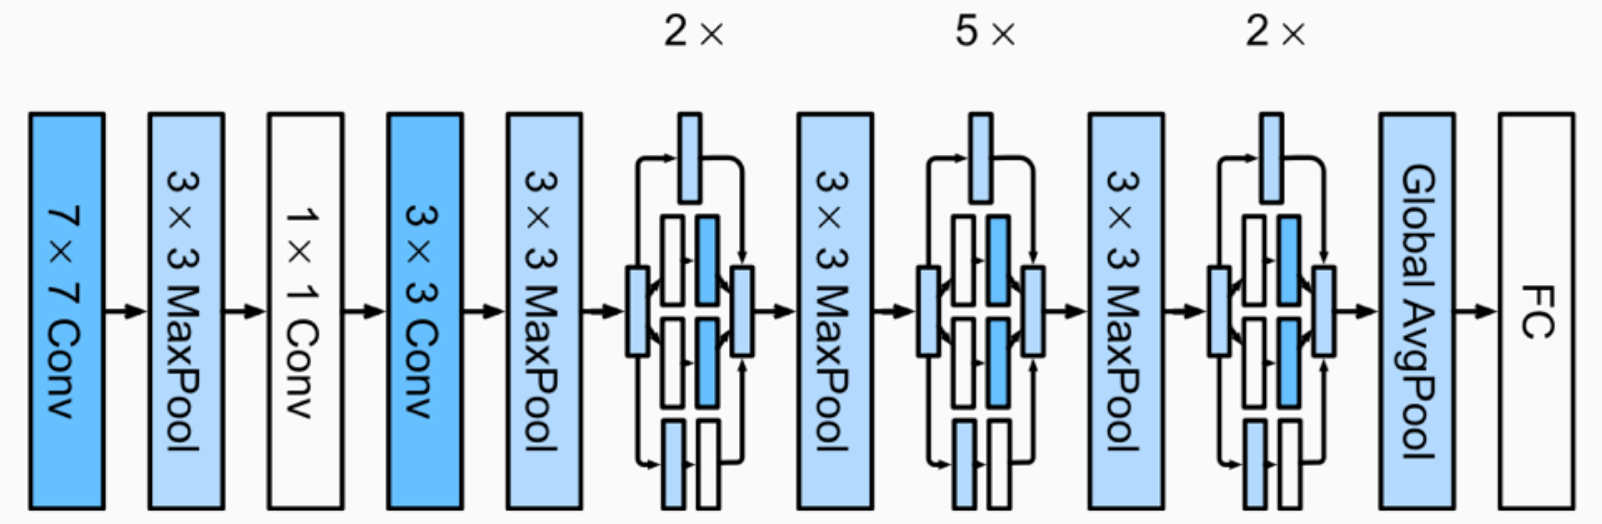

**Thiết kế:** stem (conv 3×3 + MaxPool) → 4 Inception block (có MaxPool sau block 2 và block 4) → `AdaptiveAvgPool2d(1)` → Dropout → `Linear`. Không có auxiliary classifier. Ảnh 64×64 như Bài 1. Các nhánh nối bằng `torch.cat(..., dim=1)`.

### *2.1 Inception block và GoogLeNet rút gọn*

In [17]:
# Định nghĩa Inception block
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()
        self.b1 = nn.Sequential(
            nn.Conv2d(in_ch, f1, 1), nn.ReLU())
        self.b2 = nn.Sequential(
            nn.Conv2d(in_ch, f3r, 1), nn.ReLU(),
            nn.Conv2d(f3r, f3, 3, padding=1), nn.ReLU())
        self.b3 = nn.Sequential(
            nn.Conv2d(in_ch, f5r, 1), nn.ReLU(),
            nn.Conv2d(f5r, f5, 5, padding=2), nn.ReLU())
        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_ch, fp, 1), nn.ReLU())

    def forward(self, x):
        # dim=1 là chiều channel
        return torch.cat([self.b1(x), self.b2(x),
                          self.b3(x), self.b4(x)], dim=1)


# Đối chiếu với hai block mẫu trong Lab
blk1 = InceptionBlock(1, 16, 16, 24, 4, 8, 8)
blk2 = InceptionBlock(56, 32, 32, 48, 8, 16, 16)
assert blk1(torch.rand(1, 1, 28, 28)).shape == (1, 56, 28, 28) and n_params(blk1) == 4376
assert blk2(torch.rand(1, 56, 14, 14)).shape[1] == 112 and n_params(blk2) == 22_104
print("Block mẫu: 56 channel / 4,376 tham số và 112 channel / 22,104 tham số, khớp Lab.")

Block mẫu: 56 channel / 4,376 tham số và 112 channel / 22,104 tham số, khớp Lab.


In [18]:
# GoogLeNet rút gọn: 4 Inception block, bộ tham số (f1, f3r, f3, f5r, f5, fp) cho từng block
BLOCK_CFGS = [
    (16, 16, 24, 4, 8, 8),       # block 1: in 32  -> 56
    (32, 32, 48, 8, 16, 16),     # block 2: in 56  -> 112  (đúng block thứ hai của Lab)
    (48, 48, 64, 8, 16, 16),     # block 3: in 112 -> 144
    (64, 64, 96, 12, 32, 32),    # block 4: in 144 -> 224
]
POOL_AFTER = {1, 3}              # MaxPool 2x2 sau block 2 và block 4 (chỉ số tính từ 0)


def inception_out(cfg):
    f1, f3r, f3, f5r, f5, fp = cfg
    return f1 + f3 + f5 + fp     # f3r, f5r chỉ là channel trung gian của conv 1x1


class GoogLeNetMini(nn.Module):
    def __init__(self, num_classes=21, in_ch=3, stem_ch=32, cfgs=BLOCK_CFGS,
                 pool_after=POOL_AFTER, dropout=0.3):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(in_ch, stem_ch, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2, 2))                                   # 64 -> 32
        self.blocks = nn.ModuleList()
        c = stem_ch
        for cfg in cfgs:
            self.blocks.append(InceptionBlock(c, *cfg))
            c = inception_out(cfg)                                # channel vào block sau = channel ra block trước
        self.pool_after = set(pool_after)
        self.pool = nn.MaxPool2d(2, 2)
        self.gap = nn.AdaptiveAvgPool2d(1)                        # thay cho nn.Flatten()
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(c, num_classes)
        self.out_ch = c

    def forward(self, x):
        x = self.stem(x)
        for i, blk in enumerate(self.blocks):
            x = blk(x)
            if i in self.pool_after:
                x = self.pool(x)
        return self.fc(self.drop(self.gap(x).flatten(1)))


googlenet = GoogLeNetMini(num_classes=NUM_CLASSES)
print("tổng tham số GoogLeNet rút gọn:", f"{n_params(googlenet):,}")
print("tổng tham số LeNet-5 (Bài 1)  :", f"{n_params(lenet):,}")

tổng tham số GoogLeNet rút gọn: 167,917
tổng tham số LeNet-5 (Bài 1)  : 339,421


### *2.2 Số channel output của từng Inception block (tính tay và từ code)*

In [19]:
# Số channel output của từng Inception block: tính tay (f1 + f3 + f5 + fp) và in từ code
x = googlenet.stem(torch.zeros(1, 3, 64, 64))
show("sau stem", x)
print(f"\n{'block':<7}{'in':>5}  {'tính tay f1+f3+f5+fp':<26}{'tay':>5}{'code':>6}{'shape ra':>20}{'tham số':>10}")
c_in = x.shape[1]
for i, (blk, cfg) in enumerate(zip(googlenet.blocks, BLOCK_CFGS)):
    f1, f3r, f3, f5r, f5, fp = cfg
    hand = f1 + f3 + f5 + fp
    x = blk(x)
    assert x.shape[1] == hand, "channel tính tay khác channel từ code"
    print(f"{i + 1:<7}{c_in:>5}  {f'{f1}+{f3}+{f5}+{fp}':<26}{hand:>5}{x.shape[1]:>6}{str(tuple(x.shape)[1:]):>20}{n_params(blk):>10,}")
    if i in googlenet.pool_after:
        x = googlenet.pool(x)
        print(f"{'':<7}{'':>5}  MaxPool 2x2 -> {tuple(x.shape)[1:]}")
    c_in = x.shape[1]
show("sau GAP + flatten", googlenet.gap(x).flatten(1))
logits = googlenet.eval()(torch.zeros(2, 3, 64, 64))
show("logits", logits)

sau stem                     (1, 32, 32, 32)

block     in  tính tay f1+f3+f5+fp        tay  code            shape ra   tham số
1         32  16+24+8+8                    56    56        (56, 32, 32)     5,740
2         56  32+48+16+16                 112   112       (112, 32, 32)    22,104
              MaxPool 2x2 -> (112, 16, 16)
3        112  48+64+16+16                 144   144       (144, 16, 16)    44,488
4        144  64+96+32+32                 224   224       (224, 16, 16)    89,964
              MaxPool 2x2 -> (224, 8, 8)
sau GAP + flatten            (1, 224)
logits                       (2, 21)


### *2.3 Huấn luyện và đánh giá*

[GoogLeNet rút gọn] 167,917 tham số, trainable 167,917, lr=0.001, 20 epoch


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


GoogLeNet rút gọn epoch  1/20  train 2.9722/0.0942   val 2.9053/0.1399  F1 0.0316   108.4s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


GoogLeNet rút gọn epoch  2/20  train 2.7707/0.1569   val 2.6540/0.1962  F1 0.1090   106.6s


...

GoogLeNet rút gọn epoch 18/20  train 1.8735/0.4243   val 1.8942/0.4188  F1 0.3834   106.9s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


GoogLeNet rút gọn epoch 19/20  train 1.8655/0.4154   val 1.8414/0.4323  F1 0.3966   106.3s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


GoogLeNet rút gọn epoch 20/20  train 1.8113/0.4355   val 1.8494/0.4168  F1 0.3652   105.4s
-> chọn epoch 19 (val macro-F1 0.3966), trung bình 107.0 giây/epoch

[GoogLeNet rút gọn] kết quả trên TEST:
         accuracy  precision  recall  f1_macro
giá trị    0.3924     0.4203  0.3684    0.3644


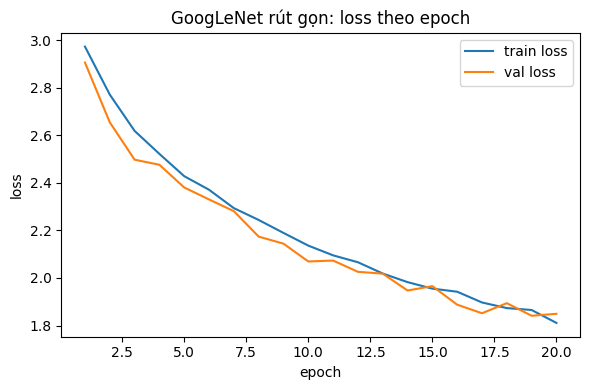

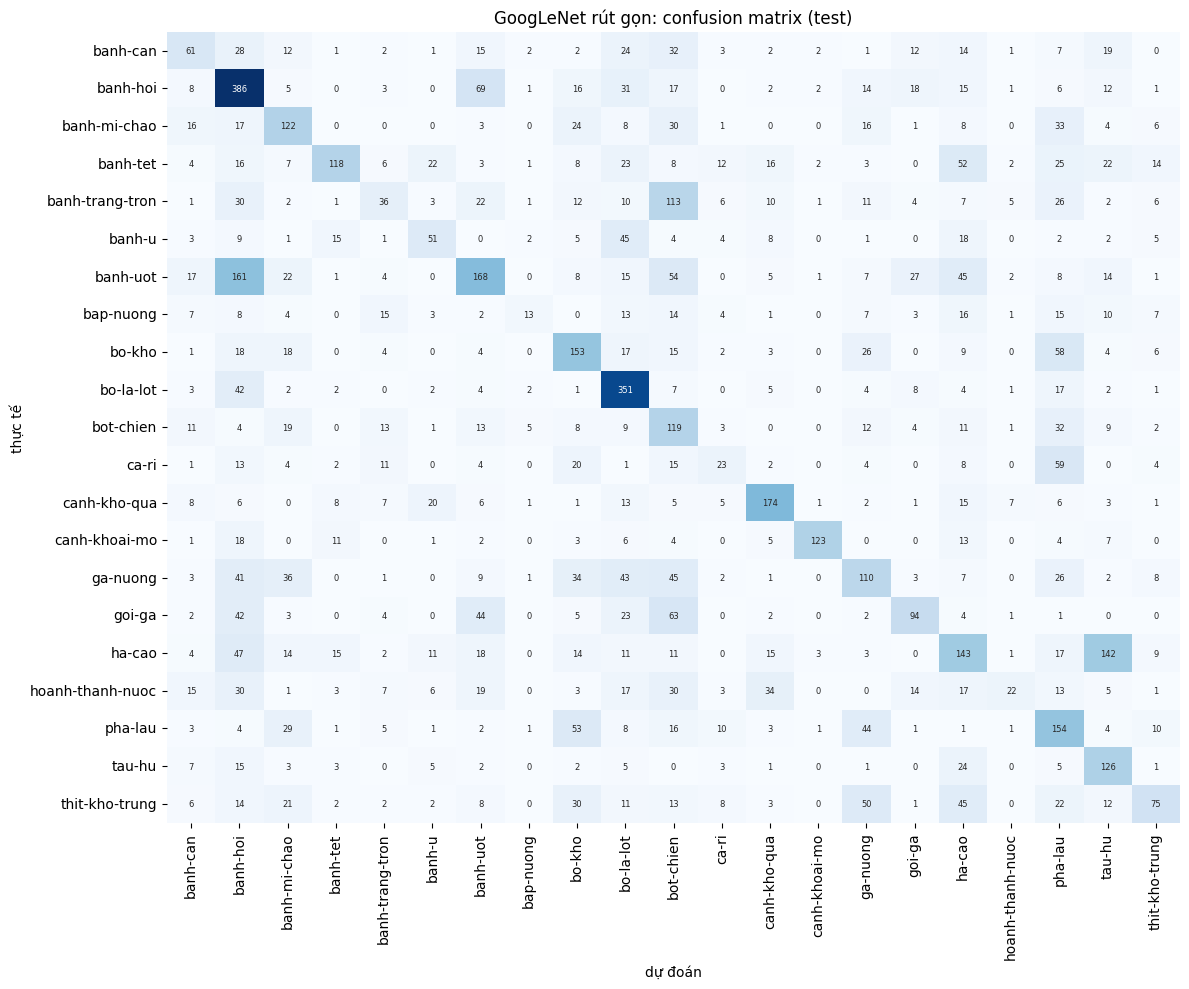

In [20]:
# Huấn luyện GoogLeNet rút gọn (cùng dữ liệu 64x64, cùng seed với Bài 1)
set_seed()
out_google = run_experiment("GoogLeNet rút gọn", GoogLeNetMini(num_classes=NUM_CLASSES),
                            loaders64, LR_SCRATCH, EPOCHS_GOOGLENET, "64×64")

### *2.4 So sánh với Bài 1*

In [21]:
# So sánh GoogLeNet với LeNet-5 (Bài 1) về tham số, thời gian mỗi epoch và macro-F1
keys = ["LeNet-5 (AvgPool)", "LeNet-5 (MaxPool)", "GoogLeNet rút gọn"]
cmp2 = pd.DataFrame({k: RESULTS[k] for k in keys}).T
cmp2 = cmp2[["params", "sec_per_epoch", "accuracy", "precision", "recall", "f1_macro"]].astype(float)
cmp2["params"] = cmp2["params"].astype(int)
display(cmp2.round(4))

ref = RESULTS["LeNet-5 (AvgPool)"]
g = RESULTS["GoogLeNet rút gọn"]
print(f"GoogLeNet / LeNet-AvgPool: tham số x{g['params'] / ref['params']:.2f}, "
      f"thời gian/epoch x{g['sec_per_epoch'] / ref['sec_per_epoch']:.2f}, "
      f"macro-F1 {g['f1_macro'] - ref['f1_macro']:+.4f}")

# F1 từng lớp của GoogLeNet
display(out_google["per_class"].round(4))
print("Các cặp bị nhầm nhiều nhất:")
display(top_confusions(out_google["cm"]))

,params,sec_per_epoch,accuracy,precision,recall,f1_macro
LeNet-5 (AvgPool),339421,109.9756,0.3113,0.3066,0.2988,0.2925
LeNet-5 (MaxPool),339421,106.2272,0.3221,0.3172,0.3098,0.2967
GoogLeNet rút gọn,167917,107.0015,0.3924,0.4203,0.3684,0.3644


GoogLeNet / LeNet-AvgPool: tham số x0.49, thời gian/epoch x0.97, macro-F1 +0.0719


,precision,recall,f1-score,support
banh-can,0.3352,0.2531,0.2884,241
banh-hoi,0.4067,0.6359,0.4961,607
banh-mi-chao,0.3754,0.4221,0.3974,289
banh-tet,0.6448,0.3242,0.4314,364
banh-trang-tron,0.2927,0.1165,0.1667,309
banh-u,0.3953,0.2898,0.3344,176
banh-uot,0.4029,0.3000,0.3439,560
bap-nuong,0.4333,0.0909,0.1503,143
bo-kho,0.3806,0.4527,0.4135,338
bo-la-lot,0.5132,0.7664,0.6147,458


Các cặp bị nhầm nhiều nhất:


,số ảnh,thực tế,bị đoán thành
0,161,banh-uot,banh-hoi
1,142,ha-cao,tau-hu
2,113,banh-trang-tron,bot-chien
3,69,banh-hoi,banh-uot
4,63,goi-ga,bot-chien
5,59,ca-ri,pha-lau
6,58,bo-kho,pha-lau
7,54,banh-uot,bot-chien
